# Introducrtion to Machine Learning: Assignment #2
## Submission date: 24\05\2026, 23:59.
### Topics:
- KNN
- Naïve Bayes
- Bayesian Decision Rule

Student1:Rawa Abu Salah  ID:325143634

Student2:Reema khalaily  ID:214281479

## Question 0 - New skills in ML
<font color='green'>Mandatory for both partners.<font>

In this question you will get familiar with OneHotEncoder and LabelEncoder, which are both very important for every ML engineer.

**OneHotEncoder** is a powerful preprocessing mechanism, allowing to translate discrete features into "continious" and yet more meaningful than just telling "1", "2", or "3".

Think about it - say we have a feature of an animal - "Horse", "Cat", "Dog". Taking Dog=2, Cat=1 will give more weighting towards dog, without any justification.

Shortly, if feature has, for example, 4 different values, we can encode them using 2 bits (and thus, creating two new binary features). <br/> You can read more about it <a href='https://www.geeksforgeeks.org/machine-learning/ml-one-hot-encoding'>here</a>.

Run the following example. Do not try to understand how the new features are constructed, but do understand how to use this tool, when dealing with discrete features, for numerical based algorithms.

In [361]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

data = pd.DataFrame([  ['apple', 'male', 1], ['orange', 'female', 2],['banana', 'male', 2],], columns=['fruit', 'gender', 'number'])

encoder = OneHotEncoder()

encoded = encoder.fit_transform(data[['fruit', 'gender']]).toarray()

df_encoded = pd.DataFrame( encoded,columns=encoder.get_feature_names_out(['fruit', 'gender']))

# add numeric column back
df_final = pd.concat([df_encoded, data[['number']]], axis=1)

print(df_final)

   fruit_apple  fruit_banana  fruit_orange  gender_female  gender_male  number
0          1.0           0.0           0.0            0.0          1.0       1
1          0.0           0.0           1.0            1.0          0.0       2
2          0.0           1.0           0.0            0.0          1.0       2


The encoder can also restore the fruit!

In [362]:
sample = [[1, 1, 1, 1, 0]] # without the "number" feature.
encoder.inverse_transform(sample)

array([['apple', 'female']], dtype=object)

**LabelEncoder** lets us handle discrete labels like {"happy", "sad"} etc. We can, during validation / test just compare `pred == true`.

However, sometimes the classification is based on the index (0-based) within the labels. For example, with gaussian bayes, we aim to maximze score $g_i(x)$ and by using `np.argmax` we get an index. Comparing it to a label will give accuracy of 0.

In [363]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

labels = [  "Mouse", "Horse", "Cat",  "Dog", "Horse", "Mouse", "Cat", "Horse", "Mouse","Cat"]

print("fifth label is", labels[0])
labels = encoder.fit_transform(labels)
print("encoded label is", labels[0])
restored = encoder.inverse_transform([labels[0]])   # note that we must send a list
print("restored label is", restored)

fifth label is Mouse
encoded label is 3
restored label is ['Mouse']


## Question 1 - Naïve Bayes
In this problem, you'll implement a basic Naïve Bayes classifier, and use it to predict the emotion raising from certain text.

You will have to classify sentences into 6 categories, <b>but could be any number.</b><br/>
The emotions are {'ambiguous', 'anger', 'fear', 'joy', 'love', 'sadness'}.

<b>Warning:</b> I haven't personally looked through all the data here. Even though the data is taken from a popular ML databases site, please accept my apologies if there are any offensive sentences.


Import libarires

In [364]:
import numpy as np
import pandas as pd
import math
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
from tqdm import tqdm

Implement the function. It reads all articles from file and returns the following data structures: <br/>
•	texall - list of documents; each entry corresponds to an article which is an array of words. <br/>
•	lbAll list of articles' labels.<br/>
•	voc - set of all distinct words in the entire data.<br/>
•	cat - set of article categories.


In [365]:
def readTrainData(file_name):
    df = pd.read_csv(file_name)

    textAll = []
    lblAll = []
    voc = set()
    cat = set()

    for i in range(len(df)):
        label = df.iloc[i, 0]
        text = str(df.iloc[i, 1])

        words = text.split()

        textAll.append(words)
        lblAll.append(label)

        voc.update(words)
        cat.add(label)

    return textAll, lblAll, voc, cat

Implement the function, which computes and returns the probabilities (on the train set):<br/>
- $P_w$ - a matrix of class-conditional probabilities, $p(x|w_i)$
- $P$ - a vector of class priors, $p(w_i)$

Make sure you deal with the case of word that appears in voc but not in class $w$.

Note: this function does not need any inputs, as the train (and test) are globaly defined below.

In [366]:
def learn_NB_text(textAll, lblAll, voc, cat, alpha=1):

    Pw = {}
    P = {}

    total_docs = len(textAll)

    for c in cat:

        docs_in_class = 0

        for label in lblAll:
            if label == c:
                docs_in_class += 1

        P[c] = docs_in_class / total_docs

        word_counts = {}

        total_words_in_class = 0

        for i in range(len(textAll)):

            if lblAll[i] == c:

                words = textAll[i]

                for word in words:

                    total_words_in_class += 1

                    if word not in word_counts:
                        word_counts[word] = 0

                    word_counts[word] += 1

        Pw[c] = {}

        for word in voc:

            count = 0

            if word in word_counts:
                count = word_counts[word]

            probability = (count + alpha ) / ( total_words_in_class + alpha * len(voc) )

            Pw[c][word] = probability

    return Pw, P

Implement fhe function that classifies all articles from the test set and computes the success rate.<br/>
Iterate over all articles of test and for each article find the most probable category.


Note: Multiplying lots of probabilities, which are between 0 and 1, can result in floating-point underflow. Since log(xy) = log(x) + log(y), it is better to perform all computations by summing logs of probabilities rather than multiplying probabilities. <br/>Class with highest final un-normalized log probability score is still the most probable.


In [367]:
def ClassifyNB_text(Pw, P):

    correct = 0

    total = len(textAll_test)

    for i in range(total):

        article = textAll_test[i]
        true_label = lblAll_test[i]

        best_class = None
        best_score = -math.inf

        for c in cat:

            score = math.log(P[c])

            for word in article:

                if word in voc:
                    score += math.log(Pw[c][word])

            if score > best_score:
                best_score = score
                best_class = c

        if best_class == true_label:
            correct += 1

    success_rate = correct / total

    return success_rate

Read the files

In [368]:
TRAIN_FILE = 'https://sharon.srworkspace.com/ml/datasets/hw1/emotions_train.csv'
TEST_FILE = 'https://sharon.srworkspace.com/ml/datasets/hw1/emotions_test.csv'

textAll_train, lblAll_train, voc, cat = readTrainData(TRAIN_FILE)

# cats must be the same at train and test
# voc of test is irrelevant - we already trained on other voc.
textAll_test, lblAll_test, _, __ = readTrainData(TEST_FILE)

Train the model, classify it on the test and report the success rate

In [369]:
Pw, P = learn_NB_text( textAll_train, lblAll_train, voc, cat, alpha=1)

acc_right = ClassifyNB_text(Pw, P)

print(acc_right)

0.7665


Try different values for alpha

100%|██████████| 10/10 [00:03<00:00,  3.05it/s]


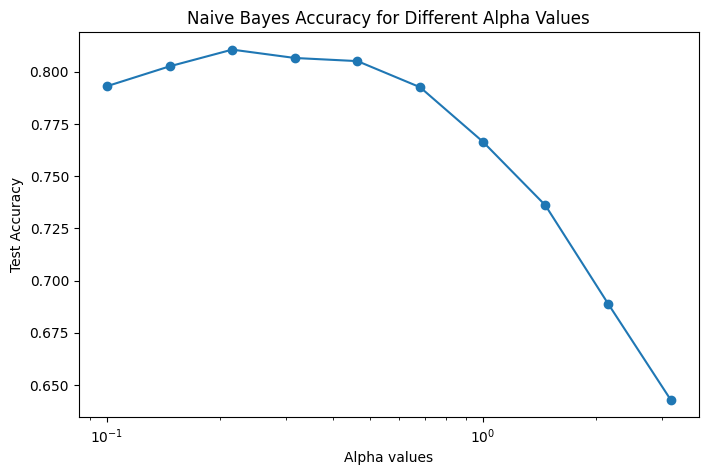

In [370]:
alpha_values = np.logspace(-1, 0.5, 10)

accuracies = []

for a in tqdm(alpha_values):

    Pw, P = learn_NB_text(textAll_train,lblAll_train,voc,cat, alpha=a )

    accuracy = ClassifyNB_text(Pw, P)

    accuracies.append(accuracy)

plt.figure(figsize=(8,5))

plt.plot(alpha_values, accuracies, marker='o')

plt.xscale('log')

plt.xlabel('Alpha values')

plt.ylabel('Test Accuracy')

plt.title('Naive Bayes Accuracy for Different Alpha Values')

plt.show()

Questions:
1. Explain why Naive Bayes still classifies well on this dataset even though the assumption of dependence is violated.
2. A word appears in the test set but never occurred in the training set for some class c. Without smoothing, what does P(word | c) become, and what does that do to the final log-posterior for class c? Use a concrete example from your own test set (identify one such word and name it) and trace what happens both with and without smoothing.
3. Look at your "accuracy vs alpha" curve. Identify one alpha value where the accuracy is noticeably worse than the best setting and explain why - which classes are hurt by that choice, and what is the mechanism? Consider the affect of alpha on frequent words and rare words.

<font color='red'>Write here your answers and explain them</font>



<font color='red'>1.1 Even though the assumption of dependence is violated Naive bayes still classifies well on the dataset because the words that appear frequently help the classifier assign the highest probability to the correct class.

<font color='red'>1.2 Without smoothing, if a word never appeared in class c, then the probability is zero :P(word∣c)=0
Since Naive Bayes multiplies probabilities we get log(0)=−infinite
so the final log-posterior for class c becomes extremely small, and the classifier will never choose this class.
in contrast with laplace smoothing the probability is small but not zero, so the class can contribute to the classification.
For example, the word “furious” that never appeared in the class “joy” during training, then without smoothing P(furious∣joy)=0</font>
</font>

1. Should we scale using StandardScaler?
2. If we were to keep the discrete features (and say, use one hot encoding), will it help to the overall performance? <br/>Which will help more - naive bayes or regular bayes?

<font color='red'>Write your answer and explain it</font>

<font color='red'>1.when we use naive base it is not nessceray to use StandardScaler because naive base works with probabilities so scaling not improve the results.

2.Using one hot encoding for discrete features can improve the results if the features contain useful information for the classifiation. Usually, it helps Naive Bayes more because  naive bayes assumws that the features are indepedent.</font>


## Question 2 - Bayesian Decision Rule

You are given the Palmer Penguins dataset. The three classes represent penguin species: Adelie, Chinstrap, and Gentoo. The features include four continuous body measurements and two categorical attributes. For this task you will use <u>only</u> the four continuous features. <br/>
Since these features are continuous, you will implement Gaussian Bayes and compare it to Gaussian naïve Bayes.

The dataset of customers is give by this url: https://srworkspace.com/sharon/ml/datasets/hw2/penguins_synth.csv

import libarires

In [371]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder

Print the table size and print the first 5 rows.

In [372]:
FILE = "https://srworkspace.com/sharon/ml/datasets/hw2/penguins_synth.csv"

df = pd.read_csv(FILE)
print(df.shape)

print(df.head())

(1000, 7)
     species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g     sex
0     Gentoo  Biscoe       46.499495      15.465332         217.222450  4909.986671    Male
1     Gentoo  Biscoe       45.864429      15.243517         212.429925  4967.676538  Female
2     Adelie  Biscoe       38.326231      16.649279         186.148113  3357.892373  Female
3  Chinstrap   Dream       46.593599      16.391835         185.677509  3473.734887    Male
4     Gentoo  Biscoe       48.801498      15.642617         215.574705  5386.212319    Male


As you don't have test, you must rely on self-created validation and hope it will be good enough.

- Convert the dataframe object to numpy.
- Handle the discrete labels.
- Split data to 80-20, random state of 42.

- Make sure to maintain the dataset priors, using stratify=y, in train_test_split method.


In [373]:
X = df[['bill_length_mm','bill_depth_mm','flipper_length_mm', 'body_mass_g']].to_numpy()
y = df['species']
encoder = LabelEncoder()
y = encoder.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

### Preprocessing

A fundamental step in learning is to check our assumptions and apply fixes if required. You will do so now.

If you want to assume gaussian distribution, you need to check if most (or all) features are gaussian distributed.<br/>
The code is attached below, but make sure it shows the features densities only.

Well, are the features gaussian?

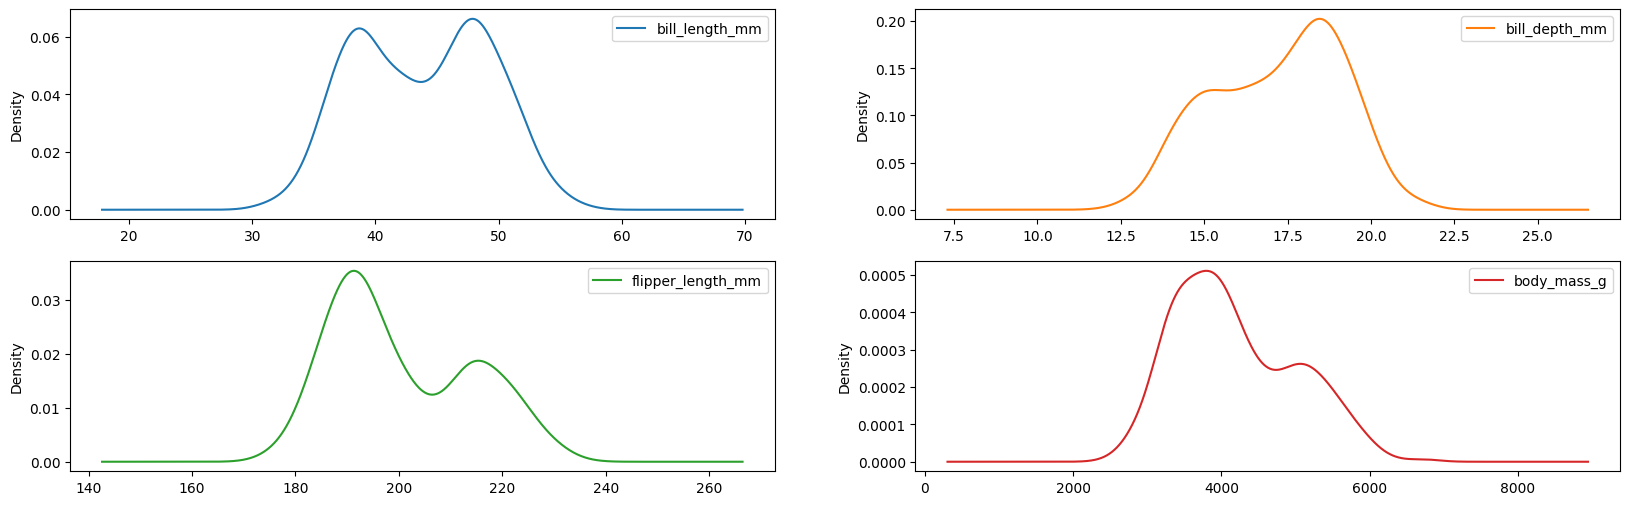

In [374]:
features_df = df[['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']]
df.plot(kind='density', subplots=True, layout=(2,2), figsize=(20, 6), sharex=False)
plt.show()

Visualize the correleation matrix of the <u>train data</u> per class.


In [375]:
pd.set_option('display.expand_frame_repr', False)
features = ['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']

classes = df['species'].unique()

for c in classes:

    print(f"\nCorrelation matrix for {c}:\n")
    class_data = df[df['species'] == c]
    corr_matrix = class_data[features].corr()
    print(corr_matrix)
    cov_matrix = np.cov(class_data[features], rowvar=False)
    det = np.linalg.det(cov_matrix)
    print(f"Determinant: {det}\n")


Correlation matrix for Gentoo:

                   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
bill_length_mm           1.000000       0.627912           0.626548     0.656502
bill_depth_mm            0.627912       1.000000           0.680142     0.719861
flipper_length_mm        0.626548       0.680142           1.000000     0.691791
body_mass_g              0.656502       0.719861           0.691791     1.000000
Determinant: 10608472.092631146


Correlation matrix for Adelie:

                   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
bill_length_mm           1.000000       0.374515           0.288768     0.531390
bill_depth_mm            0.374515       1.000000           0.288175     0.567079
flipper_length_mm        0.288768       0.288175           1.000000     0.479285
body_mass_g              0.531390       0.567079           0.479285     1.000000
Determinant: 33283596.778363638


Correlation matrix for Chinstrap:

                   bil

Print the determinant of the train data without dividing to features. Try to explain the result. Does this risk us? Can we hang on to the per-class distribution (which is not that terrible)? Why or why not?

<font color='red'>Write your answers here and explain them</font>



<font color='red'>The determinant of the covariance matrix of the train data is large and far from zero. therefore, the covariance matrix is invertible and the computation is not risky.
The correlation matrices show that some features are nearly correlated, but not corrleated enough to make the covariance matrix singular.
therefore, we can still rely on the per-class gaussian distributions, although the correlation between features means that gaussian naive bayes may be less accurate than gaussian baye </font>

### Implementing classification model

Implement the functions below. <br/>Both get train and test data $X\in\mathbb{R}^{n\times d}$. <br/>
Both return the predicted classes (vector sized n), but the naïve bayes assumes that the features are independent.

**Warnings:**
- Please use numpy for efficiency, as it will require only one loop. If you struggle, implement it as you know and optimize, step by step.
- No helper functions are allowed here

In [376]:
def classify_point_gaussian_bayes(train, test):

    if isinstance(train, tuple):
        X_train_local, y_train_local = train
    else:
        X_train_local = train
        y_train_local = y_train

    X_test = test

    classes = np.unique(y_train_local)
    scores = []

    for c in classes:
        X_class = X_train_local[y_train_local == c]

        prior = X_class.shape[0] / X_train_local.shape[0]
        mean = np.mean(X_class, axis=0)
        cov = np.cov(X_class, rowvar=False)

        cov = cov + 1e-6 * np.eye(cov.shape[0])

        inv_cov = np.linalg.inv(cov)
        det_cov = np.linalg.det(cov)

        diff = X_test - mean

        log_prob = (  np.log(prior) - 0.5 * np.log(det_cov)- 0.5 * np.sum(diff @ inv_cov * diff, axis=1) )
        scores.append(log_prob)

    scores = np.array(scores).T
    return classes[np.argmax(scores, axis=1)]


def classify_point_gaussian_naive_bayes(train, test):

    if isinstance(train, tuple):
        X_train_local, y_train_local = train
    else:
        X_train_local = train
        y_train_local = y_train

    X_test = test

    classes = np.unique(y_train_local)
    scores = []

    for c in classes:
        X_class = X_train_local[y_train_local == c]

        prior = X_class.shape[0] / X_train_local.shape[0]
        mean = np.mean(X_class, axis=0)
        var = np.var(X_class, axis=0) + 1e-6

        diff = X_test - mean

        log_prob = ( np.log(prior) - 0.5 * np.sum(np.log(var))- 0.5 * np.sum((diff ** 2) / var, axis=1))

        scores.append(log_prob)

    scores = np.array(scores).T
    return classes[np.argmax(scores, axis=1)]


x_train = X_train
x_test = X_test

For both GB and GNB, we will look at train vs test. Run the next cell and answer the following:
- Which model performed better? Why?
- Could the other model be sometimes <u>better</u>? Justify.

<font color='red'>Write here your answers and explain</font>



<font color='red'>1.Gaussian bayes achieved better results than gaussian naive bayes on both the training and testing sets.
 since the gaussian bayes consider the correlation between the features( covariance matrix.)
 In contrast, gaussian naive bayes assumes that the features are independent, while in this dataset several features are correlated.


2.gaussian naive bayes may sometimes work better on smaller datasets or in cases where the features are weakly correlated.
 Since it assumes feature independence, the model is simpler and requires estimating fewer values so it can be faster and more stable
</font>




In [377]:
# Reminder: success rate is the precentage of correctly classified data within the number of all data in the test set.

dict1 = {'GB': [], 'GNB': []}

accs = classify_point_gaussian_bayes(train=x_train, test=x_train)
dict1['GB'].append(np.count_nonzero(accs == y_train) / len(y_train))

accs = classify_point_gaussian_bayes(train=x_train, test=x_test)
dict1['GB'].append(np.count_nonzero(accs == y_test) / len(y_test))

accs = classify_point_gaussian_naive_bayes(train=x_train, test=x_train)
dict1['GNB'].append(np.count_nonzero(accs == y_train) / len(y_train))

accs = classify_point_gaussian_naive_bayes(train=x_train, test=x_test)
dict1['GNB'].append(np.count_nonzero(accs == y_test) / len(y_test))

df = pd.DataFrame(dict1, columns=['GB', 'GNB'], index=['train', 'test'])
print(df)

            GB    GNB
train  0.99125  0.975
test   0.98500  0.955


1. Should we scale using StandardScaler?
2. If we were to keep the discrete features (and say, use one hot encoding), will it help to the overall performance? <br/>Which will help more - naive bayes or regular bayes?

<font color='red'>Write your answer and explain it</font>



<font color='red'>1.  in gaussian bayes modeles it is not necessary
to use StandardScaler, because the gaussian distribution already calculates the mean and variance of each feature. but sometimes using scaling may be useful in cases when the feature ranges are different so scaling can improve the stability

2.if we keep the discrete features using one hot encoding this will improve the results because features like sex and island contain useful information about the penguin species, and this will help gaussian nauve bayes more than gaussian bayes because the features are independent </font>

Now, lets visualize!

Run the boundaries plotting for train and test with gaussian bayes.<br/>It will show the decision boundaries as saw in the lectures (do not modify it).

Explain how everything we say in the lecture aligns with the plots you see.

<font color='red'>Write here your answer and explain</font>



<font color='red'> Gaussian naive bayes assumes the features are independent, so it creates simpler decision boundaries and ignores correlations between features.
 Gaussian bayes uses the covariance matrix, so it can model feature correlations and create more flexible boundaries.</font>


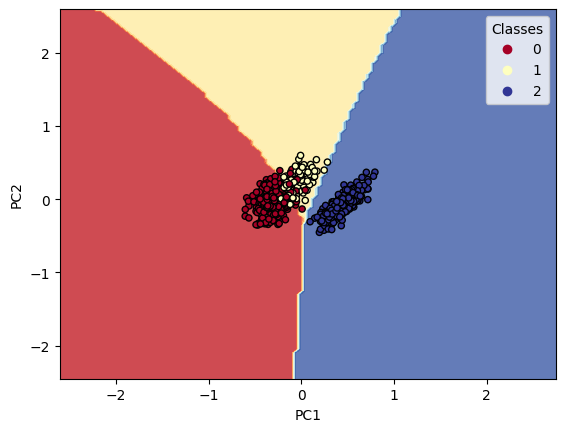

In [378]:
#@title gnb plot

from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import matplotlib.pyplot as plt

scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train)

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(x_train_scaled)

x_min, x_max = X_reduced[:, 0].min() - 2, X_reduced[:, 0].max() + 2
y_min, y_max = X_reduced[:, 1].min() - 2, X_reduced[:, 1].max() + 2
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

grid_points_2d = np.c_[xx.ravel(), yy.ravel()]

Z = classify_point_gaussian_naive_bayes(X_reduced, grid_points_2d)
Z = Z.reshape(xx.shape)

# --- Plot ---
plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.RdYlBu)

scatter = plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=y_train,
    cmap=plt.cm.RdYlBu,
    edgecolor='k',
    s=20
)

plt.xlabel('PC1')
plt.ylabel('PC2')

handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title='Classes')

plt.show()

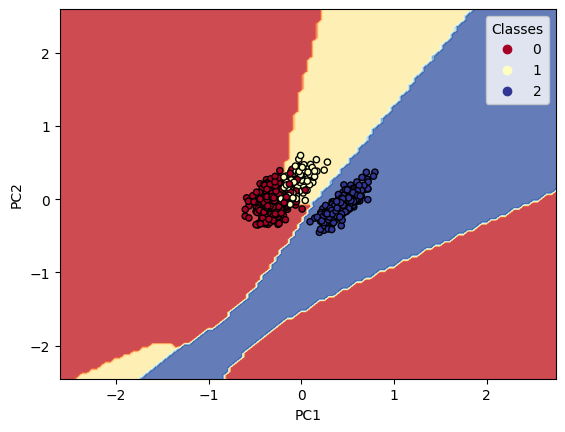

In [379]:
#@title gb plot

from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import matplotlib.pyplot as plt

# --- Scale ---
scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train)

# --- PCA ---
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(x_train_scaled)

# --- Grid ---
x_min, x_max = X_reduced[:, 0].min() - 2, X_reduced[:, 0].max() + 2
y_min, y_max = X_reduced[:, 1].min() - 2, X_reduced[:, 1].max() + 2
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

grid_points_2d = np.c_[xx.ravel(), yy.ravel()]

# ❗ Train classifier in PCA space
Z = classify_point_gaussian_bayes(X_reduced, grid_points_2d)
Z = Z.reshape(xx.shape)

# --- Plot ---
plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.RdYlBu)

scatter = plt.scatter( X_reduced[:, 0],  X_reduced[:, 1],  c=y_train,  cmap=plt.cm.RdYlBu,  edgecolor='k',  s=20)

plt.xlabel('PC1')
plt.ylabel('PC2')

handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title='Classes')

plt.show()

For curios students - Why did we plotted two features only? How does this represent the dataset?

Answer: well, you can't plot more than 3d and even there, it is terrible and not possible with contour in matplotlib. But - the method for extracting those two features is called PCA, and it gurantees to get the k most represntitive features. We will talk about it later on the course.

## Question 3 - KNN

It is time to try another approach with the pinguins.

import libraries

In [380]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

### Preprocess
Load the data just as in the previous question.<!-- use random_state=17 -->

However, this time, do not remove the discrete features, but handle them.


In [381]:
FILE = "https://srworkspace.com/sharon/ml/datasets/hw2/penguins_synth.csv"
df = pd.read_csv(FILE)

encoder_sex = LabelEncoder()
encoder_island = LabelEncoder()
encoder_species = LabelEncoder()

df['sex'] = encoder_sex.fit_transform(df['sex'])

df['island'] = encoder_island.fit_transform(df['island'])

y = encoder_species.fit_transform(df['species'])

X = df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'island', 'sex' ]].to_numpy()

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

You will compare 4 different configs:
1. Both minmax scaler for the continious features + one-hot encode for discrete features.
2. Leave continious features as they are + one-hot encode for discrete features.
3. MinMax features for the continious features only.
4. Originak continious features as they are.

You will save this as datasets dict
```
[
    {'train': .., 'test': ...},
    ...
    {'train': .., 'test': ...}
]
```
Make sure that each set is a numpy object!


In [382]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

FILE = "https://srworkspace.com/sharon/ml/datasets/hw2/penguins_synth.csv"
df = pd.read_csv(FILE)
encoder = LabelEncoder()
y = encoder.fit_transform(df['species'])

continuous_cols = ['bill_length_mm', 'bill_depth_mm','flipper_length_mm','body_mass_g']

discrete_cols = ['island','sex']

X = df[continuous_cols + discrete_cols]

X_train_df, X_test_df, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

datasets = []



ct1 = ColumnTransformer([('scale', MinMaxScaler(), continuous_cols),('onehot', OneHotEncoder(sparse_output=False), discrete_cols)])

X_train_1 = ct1.fit_transform(X_train_df)
X_test_1 = ct1.transform(X_test_df)

datasets.append({ 'train': X_train_1,'test': X_test_1})



ct2 = ColumnTransformer([('continuous', 'passthrough', continuous_cols),('onehot', OneHotEncoder(sparse_output=False), discrete_cols)])

X_train_2 = ct2.fit_transform(X_train_df)
X_test_2 = ct2.transform(X_test_df)

datasets.append({ 'train': X_train_2, 'test': X_test_2})


scaler = MinMaxScaler()

X_train_3 = scaler.fit_transform( X_train_df[continuous_cols])

X_test_3 = scaler.transform( X_test_df[continuous_cols])

datasets.append({  'train': X_train_3,  'test': X_test_3})


X_train_4 = X_train_df[continuous_cols].to_numpy()

X_test_4 = X_test_df[continuous_cols].to_numpy()

datasets.append({ 'train': X_train_4,  'test': X_test_4})

for i, ds in enumerate(datasets, start=1):
    print(i, ds['train'].shape, ds['test'].shape)

1 (800, 9) (200, 9)
2 (800, 9) (200, 9)
3 (800, 4) (200, 4)
4 (800, 4) (200, 4)


### Train

Implement the functions 'Euclidian', 'Manhattan'. <br/>
Those functions get train and test datasets ($m\times d, n\times d$) and returns the distance metric sized $m \times n$, based on the distance metric.<br/>
Reminder: Manhattan distance is $d(x,y)=\sum_{i=1}^d |x_i-y_i|$, d is the features number.


In [383]:
def Euclidean(test, data):
    diff = test[:, np.newaxis, :] - data[np.newaxis, :, :]
    distances = np.sqrt(np.sum(diff ** 2, axis=2))
    return distances

def Manhattan(test, data):
    diff = test[:, np.newaxis, :] - data[np.newaxis, :, :]
    distances = np.sum(np.abs(diff), axis=2)
    return distances

def Mahalanobis(test, data):
  distances = np.zeros((test.shape[0], data.shape[0]))
  covariance_matrix_data = np.cov(data, rowvar=False)

  # Calculate the Mahalanobis distances
  for i in range(test.shape[0]):
    diff = data - test[i]
    distances[i] = np.diag(np.sqrt(np.dot(np.dot(diff, np.linalg.inv(covariance_matrix_data)), diff.T)))
  return distances

Implement the function kNN_classify that returns array sized m, which are the predictions for the m test samples.

In [384]:
def kNN_classify(data, labels, test, k, metric='Euclidian'):
    arguments = (test, data)
    distances = eval(f'{metric}(*arguments)')

    predictions = []

    for i in range(test.shape[0]):

        # indices of k nearest neighbors
        nearest_indices = np.argsort(distances[i])[:k]

        # labels of those neighbors
        nearest_labels = labels[nearest_indices]

        # majority vote
        values, counts = np.unique(nearest_labels, return_counts=True)

        predicted_label = values[np.argmax(counts)]

        predictions.append(predicted_label)

    return np.array(predictions)

Run this cell to get all the plots. Complete missing pieces of code.
<!-- Use the train and test datasets -->

Manhattan | setting 1: 100%|██████████| 21/21 [00:00<00:00, 34.39it/s]
Manhattan | setting 2: 100%|██████████| 21/21 [00:00<00:00, 31.94it/s]
Manhattan | setting 3: 100%|██████████| 21/21 [00:00<00:00, 48.91it/s]
Manhattan | setting 4: 100%|██████████| 21/21 [00:00<00:00, 51.31it/s]
Euclidean | setting 1: 100%|██████████| 21/21 [00:00<00:00, 24.81it/s]
Euclidean | setting 2: 100%|██████████| 21/21 [00:00<00:00, 24.83it/s]
Euclidean | setting 3: 100%|██████████| 21/21 [00:00<00:00, 48.79it/s]
Euclidean | setting 4: 100%|██████████| 21/21 [00:00<00:00, 69.34it/s]


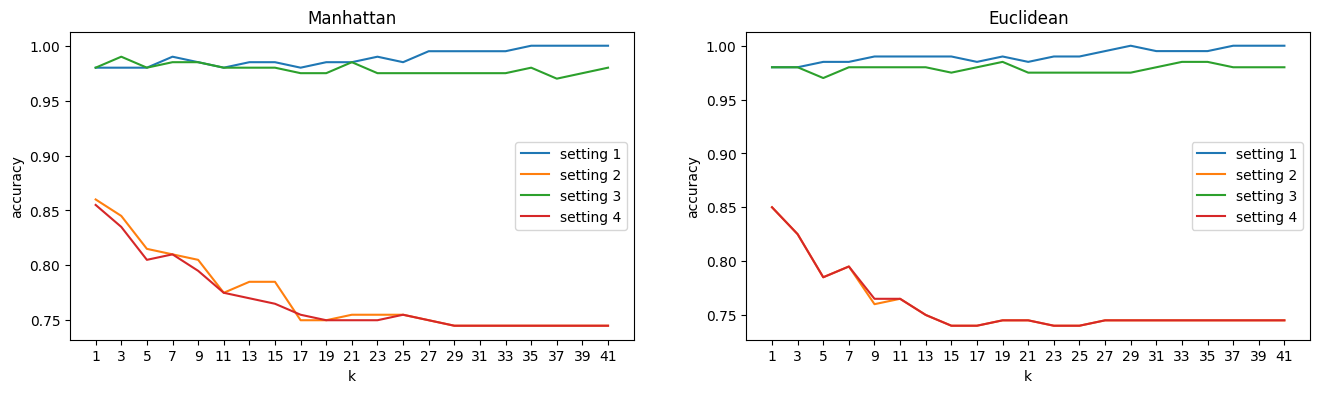

In [385]:
import matplotlib.pyplot as plt
from tqdm import tqdm

metrics = ['Manhattan', 'Euclidean']
ks = np.arange(1, 42, 2)

fig, axs = plt.subplots(1, 2, figsize=(16, 4))

for i, metric in enumerate(metrics):
    for idx, kv in enumerate(datasets, start=1):
        accs = []

        X_train = kv['train']
        y_train = y_train

        X_val = kv['test']
        y_val = y_test

        label = f'setting {idx}'

        for k in tqdm(ks, desc=f"{metric} | {label}"):
            preds = kNN_classify(X_train, y_train, X_val, k, metric=metric)
            acc = np.mean(preds == y_val)
            accs.append(acc)

        axs[i].plot(ks, accs, label=label)

    axs[i].set_xlabel('k')
    axs[i].set_ylabel('accuracy')
    axs[i].set_title(metric)
    axs[i].set_xticks(ks)
    axs[i].legend()

plt.show()

Questions:
1. Explain the output graphs, per k values.
2. Which setting was the best? Justify.
3. Which k value will you use for the test set? Why?

<font color='red'>Write your answers here, justify and explain them</font>



<font color='red'>
1.For settings 1 and 3, the accuracy stays very high, for almost all k values. this means these preprocessing settings work well for KNN.

<font color='red'>For settings 2 and 4, the accuracy decreases as k increases. this happens because the features are not scaled, so features with larger numeric ranges aaffect the distance calculation.

2.Setting 1 was the best since setting 1 uses MinMax normalization and one hot encoding which helped KNN compute distances more effectively between samples.
because all features were represented on a similar scale, the classifier produced more accurate predictions for most k value.</font>

3.i will use k=25 , in this range the accuracy is high and stable.
if we choose a small k values may overfit the training data.</font>

We didnt even try mahalanobis!

1. Run the code and try to justify what happened.
2. Find a setting of dataset among the four we crafted that will work. Compare the results obtained here vs. the results for the same setting with previous metrics. Briefly explain the differences origin.

<font color='red'>Write your answers here, justify and explain them</font>



<font color='red'>1.Mahalanobis failed in this setting because the covariance matrix became singular and could not be inverted. this happened since setting 1 includes one hot encoded discrete features, which created dependent columns in the data.

2.Mahalanobis distance worked best with setting 3, where only the continuous features were scaled. so the covariance matrix stayed stable and the model achieved very high accuracy. settings with one hot encoding were less suitable because they made the covariance matrix less stable.</font>


Mahalanobis | setting 3:   0%|          | 0/21 [00:00<?, ?it/s]/tmp/ipykernel_1439/252692944.py:18: RuntimeWarning: invalid value encountered in sqrt
  distances[i] = np.diag(np.sqrt(np.dot(np.dot(diff, np.linalg.inv(covariance_matrix_data)), diff.T)))
Mahalanobis | setting 3: 100%|██████████| 21/21 [00:09<00:00,  2.30it/s]


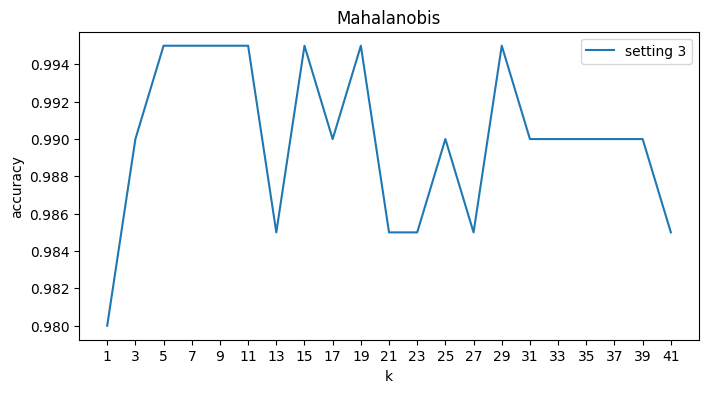

In [386]:
import matplotlib.pyplot as plt
from tqdm import tqdm

metrics = ['Mahalanobis']
ks = np.arange(1, 42, 2)

fig, ax = plt.subplots(figsize=(8, 4))

ds_setting = 2

for i, metric in enumerate(metrics):
    for idx, kv in enumerate([datasets[ds_setting]], start=1):

        accs = []

        X_train = kv['train']
        X_val = kv['test']

        label = f'setting {ds_setting + 1}'

        for k in tqdm(ks, desc=f"{metric} | {label}"):

            preds = kNN_classify(X_train, y_train, X_val, k, metric=metric)

            acc = np.mean(preds == y_test)

            accs.append(acc)

        ax.plot(ks, accs, label=label)

ax.set_xlabel('k')
ax.set_ylabel('accuracy')
ax.set_title('Mahalanobis')
ax.set_xticks(ks)
ax.legend()

plt.show()

## Question 4 - Perceptron
You are given dataset for binary classification in 2D and aim to build the best Perceptron classifier.

import libraries

In [387]:
import numpy as np
import matplotlib.pyplot as plt

In [388]:
#@title load npy file

import requests
from io import BytesIO

def load_npy_file(url):
  response = requests.get(url)
  if response.status_code == 200:
    npy_data = np.load(BytesIO(response.content), allow_pickle=True).item()
    return npy_data
  else:
    return None

Load data and make sure labels are appropriate for the perceptron algorithm

In [389]:
data_dict = load_npy_file('https://sharon.srworkspace.com/ml/datasets/hw2/perceptron_data.npy')

X_train= data_dict['X_train']
y_train = data_dict['y_train']

X_test = data_dict['X_test']
y_test = data_dict['y_test']

y_train = np.where(y_train == 0, -1, 1)
y_test = np.where(y_test == 0, -1, 1)



Implement the function `perceptron(data, labels, batch_size)` which gets the train data $X\in\mathbb{R}^{n\times d}$, labels and returns the weight vector learned by perceptron.

At each iteration, sample `batch_size` miscalssified samples and update the weights according to them.

You should return two values:
1. List of the losses from all the iterations over all the data. For example, if the loss was 10 and in the next iteration 5, return [10,5].
2. The weights w.

Demands:
- Do not use max_iterations bound here, but only gradient norm check.
- Use lr=0.05.

In [390]:
def perceptron(data, labels, batch_size):
    lr = 0.05

    n, d = data.shape
    w = np.zeros(d)
    bias = 0
    losses = []

    while True:
        scores = data @ w + bias
        predictions = np.where(scores >= 0, 1, -1)

        misclassified = np.where(predictions != labels)[0]
        loss = len(misclassified)
        losses.append(loss)

        if loss == 0:
            break

        chosen = np.random.choice(  misclassified,  size=min(batch_size, loss),  replace=False  )

        gradient_w = -np.sum(labels[chosen, None] * data[chosen], axis=0)
        gradient_b = -np.sum(labels[chosen])

        grad_norm = np.linalg.norm(gradient_w)
        if grad_norm == 0:
            break

        w = w - lr * gradient_w
        bias = bias - lr * gradient_b

    return losses, w, bias

In [391]:
#@title Ploting function
def plot(data, labels, w, bias):

    plt.scatter(data[:,0], data[:,1], c=labels)

    a, b, c = w[0], w[1], bias

    m = -a / b
    b = -c / b

    x = np.arange(0.2, 0.8, 0.1)
    y = m * x + b

    plt.plot(x, y)

    preds = np.sign(np.dot(data, w)+bias)
    acc = np.count_nonzero(labels == preds) / len(labels)
    plt.title(f"Accuracy on data is {acc}")

    plt.show()

Train the perceptron model and call the plot func' on the <u>train</u>
dataset. It prints the accurcay as the graph's title.
1. What is your conclusion about this data?
2. How would SVM react to such data? Will it perform better?

<font color='red'>Write here your answers and explain them.</font>



<font color='red'>1.The data appears to be linearly separable, because the perceptron achieved accuracy of 1.0 and found a linear line that separates the two classes.

2.SVM would also perform very well on this dataset because the data is linearly sperable, and it may even perform better since SVM finds the maximum margin separating hyperplane.</font>

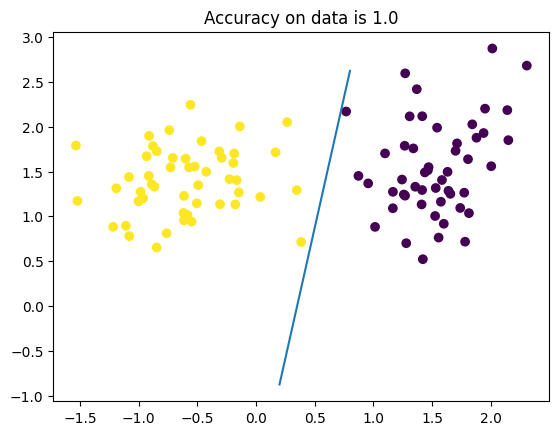

In [392]:
losses, w, bias = perceptron(X_train, y_train, batch_size=1)

plot(X_train, y_train, w, bias)

Using 1,10,20,50 batch size each time, plot a graph showing the loss as a function of the iterations number.

Explain the differences in results.

<font color='red'>Write here your answers and explain them.</font>



<font color='red'>All batch sizes reached loss = 0 at the end , which means the data is linearly separable. Batch size 1 was noisier and less stable because the model updated using only one sample each time., while larger batch sizes gave more stable updates. Batch size 10 converged the fastest in this experiment</font>

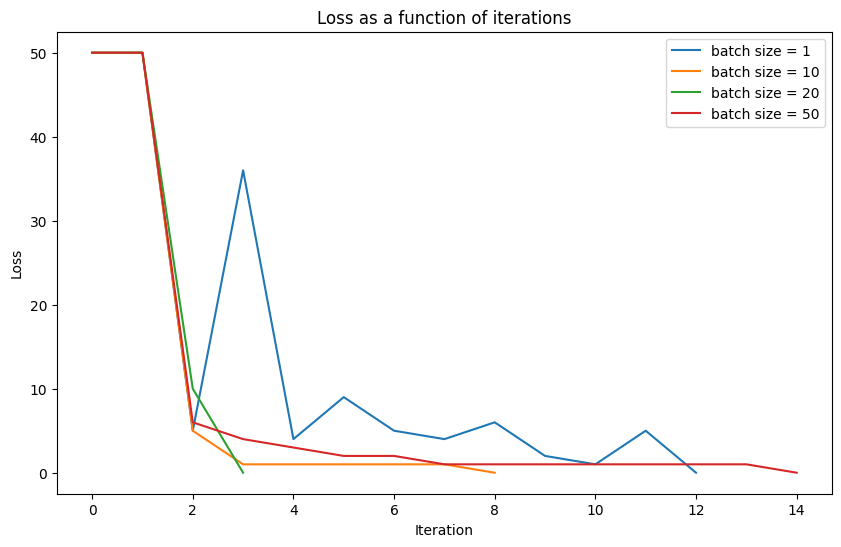

In [393]:
batch_sizes = [1, 10, 20, 50]

plt.figure(figsize=(10,6))

for batch in batch_sizes:

    losses, w, bias = perceptron(X_train, y_train, batch_size=batch)

    plt.plot(losses, label=f'batch size = {batch}')

plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Loss as a function of iterations')
plt.legend()

plt.show()

Using the optimal batch_size you specified, print the final test accuracy.

In [394]:
optimal_batch_size = 20

losses, w, bias = perceptron(X_train, y_train, batch_size=optimal_batch_size)

preds_test = np.sign(X_test @ w + bias)

test_accuracy = np.count_nonzero(preds_test == y_test) / len(y_test)

print("Final test accuracy:", test_accuracy)
print("Number of iterations:", len(losses))

Final test accuracy: 0.9
Number of iterations: 8


According to the theorem learned in lectures, how many iterations will be needed for convergence?

Check if this aligns with the results you got here.

<font color='red'>Write here your answer and explain it.</font>



<font color='red'>According to the perceptron convergence theorem that we learned in lectures, if the data is linearly separable, the perceptron is guaranteed to converge after a finite number of iterations.

In our experiment, the algorithm converged after only 8 iterations and achieved 90% test accuracy.
this matches the theorem, because the training data appears to be linearly separable, so the perceptron was able to find a separating hyperplane quickly.</font>
